# Final model explainability: post-hoc only

Tuned XGBoost was selected using validation only and finalized in Phase 11. This phase reconstructs the locked configuration on the same chronological TRAIN + VALIDATION data (42 schema-ordered features) and checks all three Phase 11 test metrics **before** calculating importance. A discrepancy stops the script. No model selection is repeated.

Run `.venv/Scripts/python.exe ml/src/explain_final_model.py`, then the same command with `--verify-reproducibility`. This notebook uses the shared saved-result loader; it does not implement a second fitting or interpretation pipeline.

TEST was already used for final held-out evaluation in Phase 11. Its use here is exclusively post-hoc verification and interpretation. No feature removal, tuning, reduced-model fitting or model-development decision follows. Predictive importance is not causal influence.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'ml/src/explain_final_model.py').is_file())
sys.path.insert(0, str(PROJECT_ROOT))
from ml.src.explain_final_model import load_saved_explanation, read_json, REPLAY_PATH
report, table = load_saved_explanation()
print(report['final_model_name'], '| features:', report['feature_count'])
print('Locked parameters:', report['selected_hyperparameters'])
print('Metric reproduction:', report['phase11_metric_reproduction'])
print(report['test_usage_statement'])
assert report['phase11_metric_reproduction']['passed']
assert len(table) == report['feature_count'] == 42
assert set(table.feature) == set(report['feature_columns'])
generated = PROJECT_ROOT / 'ml/results/generated'
generated.mkdir(parents=True, exist_ok=True)

Tuned XGBoost | features: 42
Locked parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.03, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 100, 'n_jobs': 1, 'objective': 'reg:squarederror', 'random_state': 42, 'subsample': 1.0, 'tree_method': 'hist', 'verbosity': 0}
Metric reproduction: {'absolute_differences': {'mae': 0.0, 'r2': 0.0, 'rmse': 0.0}, 'atol': 1e-09, 'expected': {'mae': 25.891124725341797, 'r2': 0.5820133686065674, 'rmse': 59.11701146812037}, 'passed': True, 'purpose': 'Equivalence check only; Phase 11 remains the final held-out evaluation', 'reconstructed': {'mae': 25.891124725341797, 'r2': 0.5820133686065674, 'rmse': 59.11701146812037}, 'rtol': 1e-09}
Phase 11 final evaluation remains unchanged. Phase 12 reuses TEST only for equivalence verification and post-hoc interpretation; no development decisions follow.


## XGBoost gain-based feature importance

Gain is the average training-objective improvement across splits using a feature, read from the fitted booster. Features never used in a split receive zero. Normalized gain divides each feature's average gain by the sum across all 42 features; it is not a share of energy consumption or a causal effect. Rank ties use alphabetical names only for reproducible presentation. All features remain in the model.

,feature,gain,gain_rank,group,normalized_gain,permutation_mean,permutation_rank,permutation_std
0,Appliances,4.836382e+06,1,Historical/current consumption,0.389234,57.157664,1,1.231037
1,appliances_lag_1,6.702494e+05,2,Historical/current consumption,0.053942,5.170825,2,0.391093
2,T6,5.279137e+05,3,Outdoor/weather,0.042487,-0.039696,41,0.026794
3,appliances_roll_mean_1h,4.347693e+05,4,Historical/current consumption,0.034990,0.418566,4,0.020876
4,hour,3.759746e+05,5,Temporal,0.030259,0.041717,9,0.040797
5,day_of_week,3.440122e+05,6,Temporal,0.027686,-0.054578,42,0.017900
6,T8,3.435862e+05,7,Indoor temperature,0.027652,0.002617,18,0.003602
7,RH_6,3.330527e+05,8,Outdoor/weather,0.026804,0.007146,14,0.005228
8,appliances_roll_std_24h,3.247521e+05,9,Historical/current consumption,0.026136,0.273785,5,0.097796
9,dow_sin,2.973213e+05,10,Temporal,0.023929,0.002325,19,0.020171


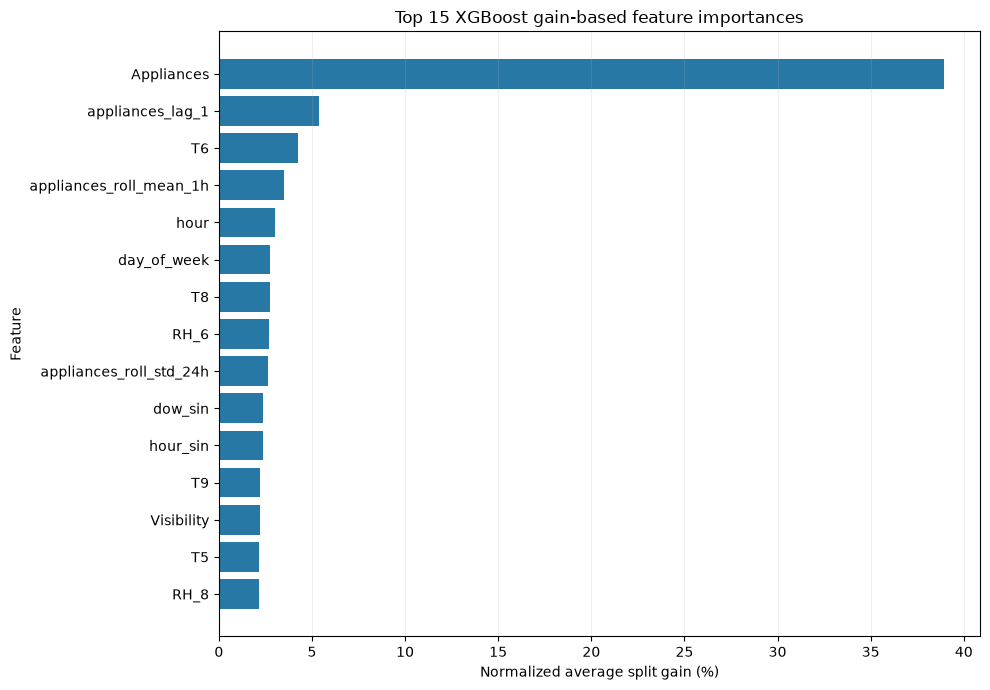

In [2]:
display(table.sort_values('gain_rank').reset_index(drop=True))
top = table.sort_values('gain_rank').head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top.feature, top.normalized_gain * 100, color='#2878A5')
ax.set(title='Top 15 XGBoost gain-based feature importances', xlabel='Normalized average split gain (%)', ylabel='Feature')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
for ext in ['png', 'pdf']:
    fig.savefig(generated / ('phase12_top15_gain.' + ext), dpi=200, bbox_inches='tight')
plt.show()

## Held-out TEST permutation importance

`sklearn.inspection.permutation_importance` uses negative RMSE scoring, ten repeats, random state 42, one worker and all test rows. Importance equals **permuted RMSE minus baseline RMSE**, in Wh. Positive values mean shuffling worsens error; negative values mean shuffling improves error. Negative values are retained.

Error bars show one standard deviation across repeated permutations (ddof=0), not confidence intervals. Row permutations break serial dependence and cross-feature correlations, potentially creating implausible combinations. These are perturbation diagnostics, not operational forecast estimates or intervention effects.

,feature,gain,gain_rank,group,normalized_gain,permutation_mean,permutation_rank,permutation_std
0,Appliances,4.836382e+06,1,Historical/current consumption,0.389234,57.157664,1,1.231037
1,appliances_lag_1,6.702494e+05,2,Historical/current consumption,0.053942,5.170825,2,0.391093
2,hour_cos,2.385740e+05,18,Temporal,0.019201,0.601365,3,0.122768
3,appliances_roll_mean_1h,4.347693e+05,4,Historical/current consumption,0.034990,0.418566,4,0.020876
4,appliances_roll_std_24h,3.247521e+05,9,Historical/current consumption,0.026136,0.273785,5,0.097796
5,hour_sin,2.972595e+05,11,Temporal,0.023924,0.146738,6,0.124884
6,appliances_roll_std_1h,2.499067e+05,17,Historical/current consumption,0.020113,0.110611,7,0.029862
7,appliances_lag_6,2.502853e+05,16,Historical/current consumption,0.020143,0.094721,8,0.019296
8,hour,3.759746e+05,5,Temporal,0.030259,0.041717,9,0.040797
9,T3,1.654582e+05,25,Indoor temperature,0.013316,0.033871,10,0.011328


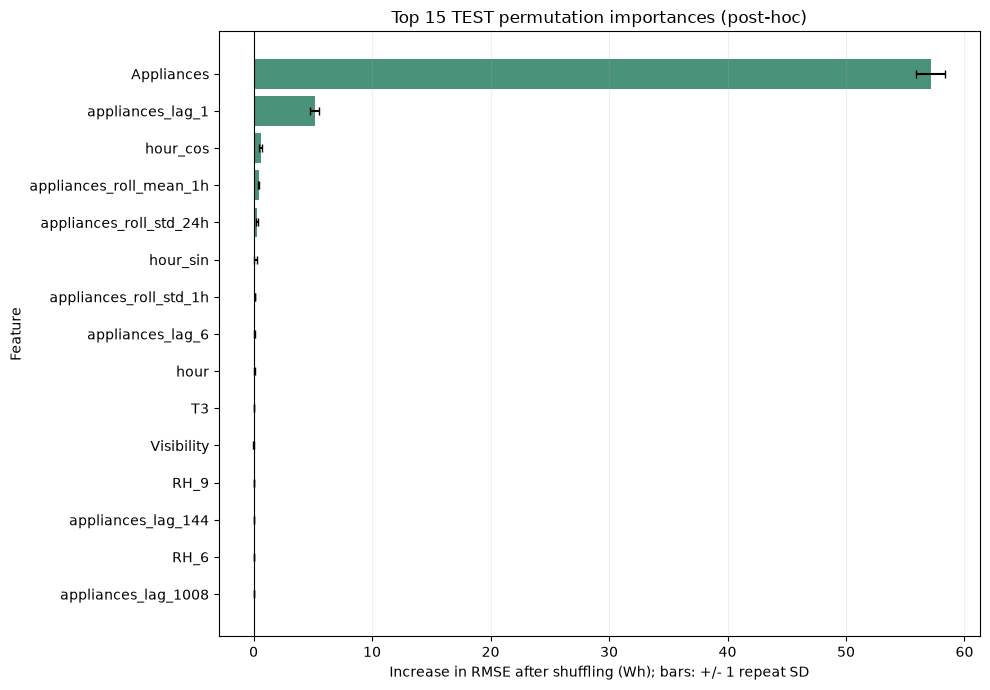

In [3]:
display(table.sort_values('permutation_rank').reset_index(drop=True))
top = table.sort_values('permutation_rank').head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top.feature, top.permutation_mean, xerr=top.permutation_std, capsize=3, color='#4B927A')
ax.axvline(0, color='black', linewidth=0.8)
ax.set(title='Top 15 TEST permutation importances (post-hoc)', xlabel='Increase in RMSE after shuffling (Wh); bars: +/- 1 repeat SD', ylabel='Feature')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
for ext in ['png', 'pdf']:
    fig.savefig(generated / ('phase12_top15_permutation.' + ext), dpi=200, bbox_inches='tight')
plt.show()

## Compare the methods

Gain describes fitted training splits, whereas permutation importance describes test-score sensitivity. Rankings need not agree. Correlated inputs may substitute for each other and mask individual permutation importance, while a tree may preferentially split on one of them. Low importance does not establish that a feature is inherently useless. No feature is removed.

For descriptive reporting only, very low absolute permutation importance was fixed as |mean| <= 0.1 Wh before calculation. Top-ten overlap and method-specific rankings are calculated below.

In [4]:
print('Top 10 in both methods:', report['top_10_overlap'])
print('Top 10 gain only:', report['top_10_gain_only'])
print('Top 10 permutation only:', report['top_10_permutation_only'])
print('Very low absolute permutation importance (<= 0.1 Wh):', report['very_low_absolute_permutation_features'])
print('Negative mean permutation importance:', report['negative_permutation_features'])
display(table[['feature', 'gain_rank', 'permutation_rank', 'normalized_gain', 'permutation_mean', 'permutation_std']].sort_values('gain_rank'))

Top 10 in both methods: ['Appliances', 'appliances_lag_1', 'appliances_roll_mean_1h', 'hour', 'appliances_roll_std_24h']
Top 10 gain only: ['T6', 'day_of_week', 'T8', 'RH_6', 'dow_sin']
Top 10 permutation only: ['hour_cos', 'hour_sin', 'appliances_roll_std_1h', 'appliances_lag_6', 'T3']
Very low absolute permutation importance (<= 0.1 Wh): ['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'hour', 'day_of_week', 'month', 'is_weekend', 'dow_sin', 'dow_cos', 'appliances_lag_6', 'appliances_lag_144', 'appliances_lag_1008', 'appliances_roll_mean_24h']
Negative mean permutation importance: ['lights', 'T6', 'day_of_week']


,feature,gain_rank,permutation_rank,normalized_gain,permutation_mean,permutation_std
0,Appliances,1,1,0.389234,57.157664,1.231037
1,appliances_lag_1,2,2,0.053942,5.170825,0.391093
2,T6,3,41,0.042487,-0.039696,0.026794
3,appliances_roll_mean_1h,4,4,0.034990,0.418566,0.020876
4,hour,5,9,0.030259,0.041717,0.040797
5,day_of_week,6,42,0.027686,-0.054578,0.017900
6,T8,7,18,0.027652,0.002617,0.003602
7,RH_6,8,14,0.026804,0.007146,0.005228
8,appliances_roll_std_24h,9,5,0.026136,0.273785,0.097796
9,dow_sin,10,19,0.023929,0.002325,0.020171


## Feature groups and historical consumption

Groups follow `data/raw/README.md` and the approved Phase 5 schema: current/history, temporal, lighting, indoor temperature, indoor humidity and outdoor/weather. T6 and RH_6 belong to outdoor/weather. Normalized average gains are summed descriptively by group; this is not a group share of energy or total split loss reduction. Individual permutation scores are not summed because feature interactions and dependence make this misleading.

Current Appliances and lag indices are relative to forecast origin t: lags 1/6/144/1008 refer to t-10 minutes/t-1 hour/t-24 hours/t-7 days. Rolling windows end at t and include the current observation. Inspect current, lag and rolling features without assuming short-term history dominates.

In [5]:
groups = pd.Series(report['group_normalized_gain_totals'], name='Normalized average gain')
display(groups.to_frame())
print('Historical/current normalized gain (%):', 100 * groups['Historical/current consumption'])
print('Historical/current features in gain top 10:', report['historical_features_in_gain_top10'])
print('Historical/current features in permutation top 10:', report['historical_features_in_permutation_top10'])
display(table.loc[table.group.eq('Historical/current consumption')].sort_values('gain_rank'))
if groups['Historical/current consumption'] > 0.5 and report['top_10_gain_features'][0]['feature'] == 'Appliances' and report['top_10_permutation_features'][0]['feature'] == 'Appliances':
    print('Calculated conclusion: current/historical consumption dominates normalized gain, and current Appliances leads both rankings. This supports short-horizon predictive reliance, not a causal claim.')
else:
    print('Historical contribution is described by the calculated scores above; broad dominance is not asserted.')

,Normalized average gain
Historical/current consumption,0.572892
Indoor humidity,0.039838
Indoor temperature,0.138452
Lighting,0.014772
Outdoor/weather,0.109048
Temporal,0.124997


Historical/current normalized gain (%): 57.28921397404149
Historical/current features in gain top 10: 4
Historical/current features in permutation top 10: 6


,feature,gain,gain_rank,group,normalized_gain,permutation_mean,permutation_rank,permutation_std
0,Appliances,4.836382e+06,1,Historical/current consumption,0.389234,57.157664,1,1.231037
1,appliances_lag_1,6.702494e+05,2,Historical/current consumption,0.053942,5.170825,2,0.391093
3,appliances_roll_mean_1h,4.347693e+05,4,Historical/current consumption,0.034990,0.418566,4,0.020876
8,appliances_roll_std_24h,3.247521e+05,9,Historical/current consumption,0.026136,0.273785,5,0.097796
15,appliances_lag_6,2.502853e+05,16,Historical/current consumption,0.020143,0.094721,8,0.019296
16,appliances_roll_std_1h,2.499067e+05,17,Historical/current consumption,0.020113,0.110611,7,0.029862
19,appliances_lag_1008,2.253886e+05,20,Historical/current consumption,0.018139,0.005825,15,0.005315
25,appliances_lag_144,1.266741e+05,26,Historical/current consumption,0.010195,0.007559,13,0.006074
38,appliances_roll_mean_24h,0.000000e+00,39,Historical/current consumption,0.000000,0.000000,36,0.000000


Calculated conclusion: current/historical consumption dominates normalized gain, and current Appliances leads both rankings. This supports short-horizon predictive reliance, not a causal claim.


## Environmental, temporal and lighting interpretation

The category tables show the strongest calculated temperature, humidity and weather inputs under each method, plus all temporal and lighting scores. These are descriptive views of the same 42 features. All-location temperature includes T1-T9, T_out and Tdewpoint; indoor-only subsets are shown separately.

Phase 3 exploratory output reported weak marginal relationships with contemporaneous Appliances (for example lights r approximately 0.197, RH_out -0.152, T2 0.120, T6 0.118, T_out 0.099). Those existing EDA values describe a different quantity than conditional next-step model importance. Weak marginal correlation does not rule out usefulness in a nonlinear multivariable model; neither measure establishes physical causation.

Temporal results cover only January-May, with partial January and May, so full-year seasonal generalization is unsupported. `lights` is lighting energy, not an occupancy sensor.

In [6]:
for category in ['temperature_all_locations', 'indoor_temperature', 'humidity_all_locations', 'indoor_humidity', 'outdoor_weather']:
    ranks = report['category_rankings'][category]
    print(category, '| strongest by gain:', ranks['by_gain'][0]['feature'], '| strongest by permutation:', ranks['by_permutation'][0]['feature'])
    display(pd.DataFrame(ranks['by_gain'])[['feature', 'normalized_gain', 'gain_rank', 'permutation_mean', 'permutation_std', 'permutation_rank']])
print('Temporal features:')
display(table.loc[table.group.eq('Temporal')].sort_values('gain_rank'))
print('Lighting:')
display(table.loc[table.feature.eq('lights')])

temperature_all_locations | strongest by gain: T6 | strongest by permutation: T3


,feature,normalized_gain,gain_rank,permutation_mean,permutation_std,permutation_rank
0,T6,0.042487,3,-0.039696,0.026794,41
1,T8,0.027652,7,0.002617,0.003602,18
2,T9,0.022009,12,0.000000,0.000000,32
3,T5,0.021491,14,0.000000,0.000000,30
4,T7,0.018822,19,0.000000,0.000000,31
5,T4,0.018078,21,0.000000,0.000000,29
6,Tdewpoint,0.017802,22,0.000000,0.000000,34
7,T2,0.017083,23,0.000000,0.000000,28
8,T3,0.013316,25,0.033871,0.011328,10
9,T1,0.000000,36,0.000000,0.000000,27


indoor_temperature | strongest by gain: T8 | strongest by permutation: T3


,feature,normalized_gain,gain_rank,permutation_mean,permutation_std,permutation_rank
0,T8,0.027652,7,0.002617,0.003602,18
1,T9,0.022009,12,0.000000,0.000000,32
2,T5,0.021491,14,0.000000,0.000000,30
3,T7,0.018822,19,0.000000,0.000000,31
4,T4,0.018078,21,0.000000,0.000000,29
5,T2,0.017083,23,0.000000,0.000000,28
6,T3,0.013316,25,0.033871,0.011328,10
7,T1,0.000000,36,0.000000,0.000000,27


humidity_all_locations | strongest by gain: RH_6 | strongest by permutation: RH_9


...

,feature,normalized_gain,gain_rank,permutation_mean,permutation_std,permutation_rank
0,T6,0.042487,3,-0.039696,0.026794,41
1,RH_6,0.026804,8,0.007146,0.005228,14
2,Visibility,0.021955,13,0.019178,0.030953,11
3,Tdewpoint,0.017802,22,0.000000,0.000000,34
4,Press_mm_hg,0.000000,29,0.000000,0.000000,20
5,RH_out,0.000000,35,0.000000,0.000000,26
6,T_out,0.000000,37,0.000000,0.000000,33
7,Windspeed,0.000000,38,0.000000,0.000000,35


Temporal features:


,feature,gain,gain_rank,group,normalized_gain,permutation_mean,permutation_rank,permutation_std
4,hour,375974.625000,5,Temporal,0.030259,0.041717,9,0.040797
5,day_of_week,344012.156250,6,Temporal,0.027686,-0.054578,42,0.017900
9,dow_sin,297321.312500,10,Temporal,0.023929,0.002325,19,0.020171
10,hour_sin,297259.468750,11,Temporal,0.023924,0.146738,6,0.124884
17,hour_cos,238574.015625,18,Temporal,0.019201,0.601365,3,0.122768
39,dow_cos,0.000000,40,Temporal,0.000000,0.000000,37,0.000000
40,is_weekend,0.000000,41,Temporal,0.000000,0.000000,38,0.000000
41,month,0.000000,42,Temporal,0.000000,0.000000,39,0.000000


Lighting:


,feature,gain,gain_rank,group,normalized_gain,permutation_mean,permutation_rank,permutation_std
23,lights,183551.6875,24,Lighting,0.014772,-0.003965,40,0.003261


## Verification and limitations

This analysis interprets a fixed model for one building and test period. Correlated input substitution, serial dependence and permutation-induced unrealistic combinations limit inference. Repeat variation is not population uncertainty. Importance does not establish causal effects, occupancy evidence, physical control or energy savings.

The complete workflow is rerun with identical model, data, environment and permutation seed. The record below verifies metrics, gains and every permutation result. Phase 11 artifacts and split checksums remain unchanged. No SHAP, alternative model, feature selection, tuning or production-model artifact is introduced. Phase 12 ends here; Phase 13 is not started.

References: [XGBoost Booster.get_score](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.Booster.get_score), [scikit-learn permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).

In [7]:
display(read_json(REPLAY_PATH))
assert read_json(REPLAY_PATH)['whole_result_reproduced_exactly']
assert report['input_checksums_unchanged']
for field in ['model_changed', 'feature_selection_performed', 'tuning_performed', 'alternative_models_evaluated', 'test_influenced_model_development', 'model_artifact_saved']:
    assert report[field] is False
print('All Phase 12 notebook checks passed.')

{'comparison': 'Exact JSON numeric equality; no tolerance was needed',
 'gain_reproduced_exactly': True,
 'original_result_sha256': 'f1c0ce2cb196accd00c78ce6a0d1158716dc03967ff7e963a11a4e207101a5b0',
 'permutation_means_stds_and_all_repetitions_reproduced_exactly': True,
 'phase11_metrics_reproduced': True,
 'whole_result_reproduced_exactly': True}

All Phase 12 notebook checks passed.
